In [20]:
import pandas as pd

df = pd.read_csv("../data/1_semestre_2026.csv", sep=";", decimal=",")
df.head()

,Regiao - Sigla,Estado - Sigla,Municipio,Revenda,CNPJ da Revenda,Nome da Rua,Numero Rua,Complemento,Bairro,Cep,Produto,Data da Coleta,Valor de Venda,Valor de Compra,Unidade de Medida,Bandeira
0,N,AC,CRUZEIRO DO SUL,AMAZONIA COMERCIO DE DERIVADOS DE PETROLEO LTDA,01.492.748/0003-83,AVENIDA COPACABANA,440,NaN,COPACABANA,69980-000,GASOLINA,02/01/2026,7.97,NaN,R$ / litro,IPIRANGA
1,N,AC,CRUZEIRO DO SUL,AMAZONIA COMERCIO DE DERIVADOS DE PETROLEO LTDA,01.492.748/0003-83,AVENIDA COPACABANA,440,NaN,COPACABANA,69980-000,DIESEL,02/01/2026,8.15,NaN,R$ / litro,IPIRANGA
2,N,AC,CRUZEIRO DO SUL,AMAZONIA COMERCIO DE DERIVADOS DE PETROLEO LTDA,01.492.748/0003-83,AVENIDA COPACABANA,440,NaN,COPACABANA,69980-000,DIESEL S10,02/01/2026,8.17,NaN,R$ / litro,IPIRANGA
3,N,AC,RIO BRANCO,AUTO POSTO AMAPA LTDA,00.529.581/0001-53,VIA CHICO MENDES,3570,NaN,AREAL,69906-119,GASOLINA,02/01/2026,7.29,NaN,R$ / litro,VIBRA
4,N,AC,RIO BRANCO,AUTO POSTO AMAPA LTDA,00.529.581/0001-53,VIA CHICO MENDES,3570,NaN,AREAL,69906-119,GASOLINA ADITIVADA,02/01/2026,7.39,NaN,R$ / litro,VIBRA


In [21]:
df.shape

(422418, 16)

In [22]:
df["Produto"].value_counts()

Produto
GASOLINA              110925
ETANOL                 93893
GASOLINA ADITIVADA     86231
DIESEL S10             77118
DIESEL                 45814
GNV                     8437
Name: count, dtype: int64

In [23]:
df["Data da Coleta"] = pd.to_datetime(df["Data da Coleta"], format="%d/%m/%Y")

In [24]:
df.groupby("Produto")["Valor de Venda"].mean()

Produto
DIESEL                6.760093
DIESEL S10            6.887436
ETANOL                4.709595
GASOLINA              6.563056
GASOLINA ADITIVADA    6.760228
GNV                   4.538153
Name: Valor de Venda, dtype: float64

<Axes: xlabel='Produto'>

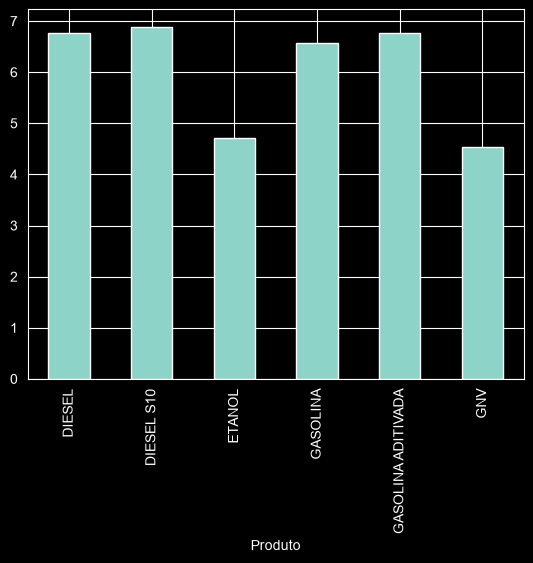

In [25]:
df.groupby("Produto")["Valor de Venda"].mean().plot(kind="bar")

<Axes: title={'center': 'Preço médio por combustível (1º semestre 2026)'}, xlabel='Produto', ylabel='Preço (R$)'>

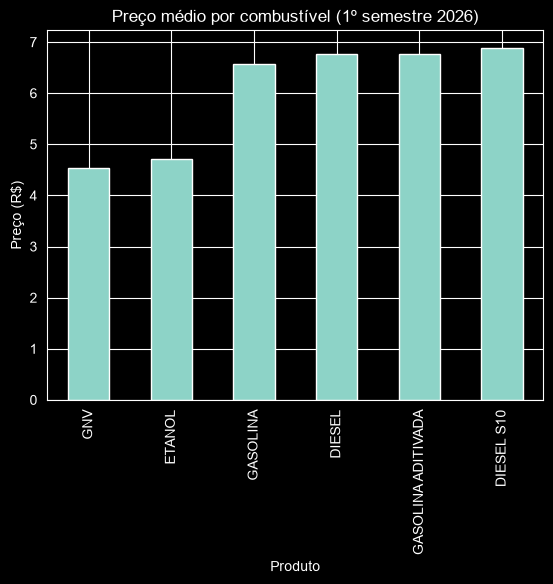

In [26]:
df.groupby("Produto")["Valor de Venda"].mean().sort_values().plot(
    kind="bar",
    title="Preço médio por combustível (1º semestre 2026)",
    ylabel="Preço (R$)"
)

In [27]:
gasolina = df[df["Produto"] == "GASOLINA"]

In [29]:
gasolina.groupby("Estado - Sigla")["Valor de Venda"].mean().sort_values(ascending=False).head(27)

Estado - Sigla
AC    7.478528
RR    7.439543
AM    7.305192
RO    7.211197
BA    7.020079
SE    6.953316
TO    6.923531
PE    6.843910
RN    6.754544
CE    6.731664
PA    6.711134
AL    6.680080
PR    6.659244
MT    6.648261
SC    6.594937
RJ    6.554545
GO    6.541775
MA    6.505531
ES    6.496095
MS    6.475033
RS    6.446283
AP    6.435356
DF    6.433609
SP    6.423757
PI    6.396110
PB    6.344294
MG    6.335680
Name: Valor de Venda, dtype: float64

<Axes: title={'center': 'Preço médio da gasolina ao longo do semestre'}, xlabel='Data da Coleta', ylabel='Preço (R$)'>

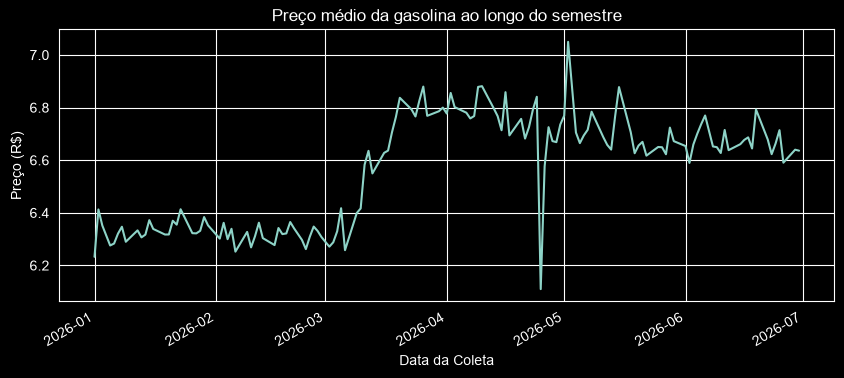

In [30]:
gasolina.groupby("Data da Coleta")["Valor de Venda"].mean().plot(
    figsize=(10, 4),
    title="Preço médio da gasolina ao longo do semestre",
    ylabel="Preço (R$)"
)

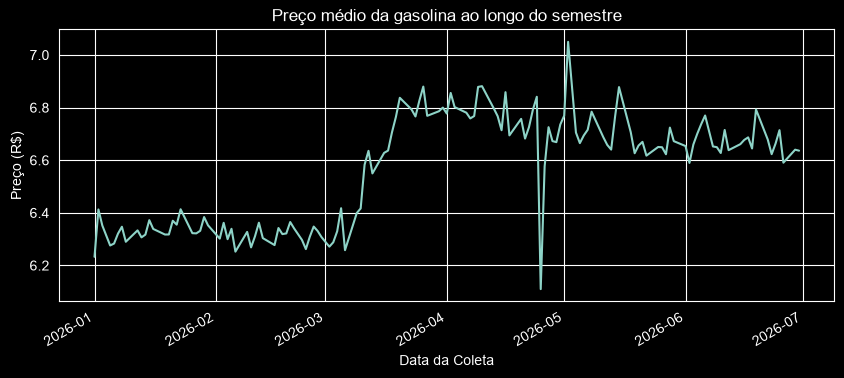

In [32]:
ax = gasolina.groupby("Data da Coleta")["Valor de Venda"].mean().plot(
    figsize=(10, 4),
    title="Preço médio da gasolina ao longo do semestre",
    ylabel="Preço (R$)"
)
ax.figure.savefig("../imagens/gasolina_semestre.png", dpi=150, bbox_inches="tight")

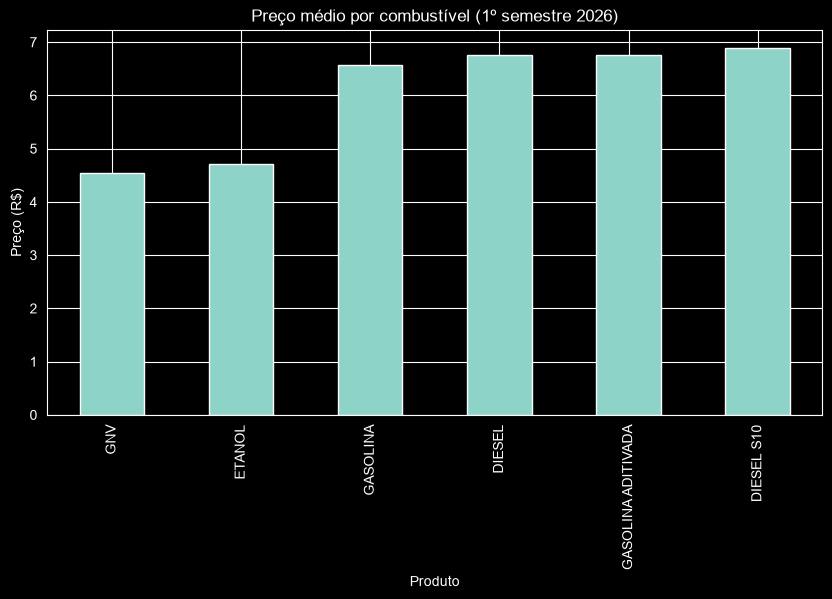

In [34]:
ax = df.groupby("Produto")["Valor de Venda"].mean().sort_values().plot(
    kind="bar",
    figsize=(10, 5),
    title="Preço médio por combustível (1º semestre 2026)",
    ylabel="Preço (R$)"
)
ax.figure.savefig("../imagens/preco_por_combustivel.png", dpi=150, bbox_inches="tight")